In [14]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import requests
import zipfile
from io import BytesIO

# Download the MovieLens dataset
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

response = requests.get(url)
response.raise_for_status()

# Extract the dataset
with zipfile.ZipFile(BytesIO(response.content)) as zip_file:
    with zip_file.open("ml-latest-small/ratings.csv") as file:
        ratings = pd.read_csv(file)

    with zip_file.open("ml-latest-small/movies.csv") as file:
        movies = pd.read_csv(file)

# Display the first five ratings
print("Movie Ratings Dataset:")
display(ratings.head())

print("\nMovie Information Dataset:")
display(movies.head())

Movie Ratings Dataset:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931



Movie Information Dataset:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [15]:
# Check the shapes of both datasets
print("Ratings Dataset Shape:", ratings.shape)
print("Movies Dataset Shape:", movies.shape)

# Display column names
print("\nRatings Dataset Columns:")
print(ratings.columns.tolist())

print("\nMovies Dataset Columns:")
print(movies.columns.tolist())

# Check ratings dataset information
print("\nRatings Dataset Information:")
ratings.info()

# Check movies dataset information
print("\nMovies Dataset Information:")
movies.info()

# Check for missing values
print("\nMissing Values in Ratings:")
print(ratings.isnull().sum())

print("\nMissing Values in Movies:")
print(movies.isnull().sum())

# Display summary statistics for ratings
print("\nRatings Summary:")
display(ratings.describe())

Ratings Dataset Shape: (100836, 4)
Movies Dataset Shape: (9742, 3)

Ratings Dataset Columns:
['userId', 'movieId', 'rating', 'timestamp']

Movies Dataset Columns:
['movieId', 'title', 'genres']

Ratings Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

Movies Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ K

,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


In [16]:
# Check for duplicate records
print("Duplicate ratings:", ratings.duplicated().sum())
print("Duplicate movies:", movies.duplicated().sum())

# Remove duplicate records
ratings.drop_duplicates(inplace=True)
movies.drop_duplicates(inplace=True)

# Remove rows with missing essential information
ratings.dropna(subset=["userId", "movieId", "rating"], inplace=True)
movies.dropna(subset=["movieId", "title"], inplace=True)

# Ensure ratings are numeric
ratings["rating"] = pd.to_numeric(ratings["rating"], errors="coerce")
ratings.dropna(subset=["rating"], inplace=True)

# Merge ratings with movie information
movie_data = pd.merge(
    ratings,
    movies,
    on="movieId",
    how="inner"
)

# Convert timestamp into a readable date
movie_data["rating_date"] = pd.to_datetime(
    movie_data["timestamp"],
    unit="s",
    errors="coerce"
)

# Display the cleaned dataset
print("Cleaned Ratings Dataset Shape:", ratings.shape)
print("Cleaned Movies Dataset Shape:", movies.shape)
print("Combined Dataset Shape:", movie_data.shape)

display(movie_data.head())

Duplicate ratings: 0
Duplicate movies: 0
Cleaned Ratings Dataset Shape: (100836, 4)
Cleaned Movies Dataset Shape: (9742, 3)
Combined Dataset Shape: (100836, 7)


,userId,movieId,rating,timestamp,title,genres,rating_date
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,2000-07-30 18:45:03
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance,2000-07-30 18:20:47
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller,2000-07-30 18:37:04
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,2000-07-30 19:03:35
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,2000-07-30 18:48:51


Distribution of Movie Ratings:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


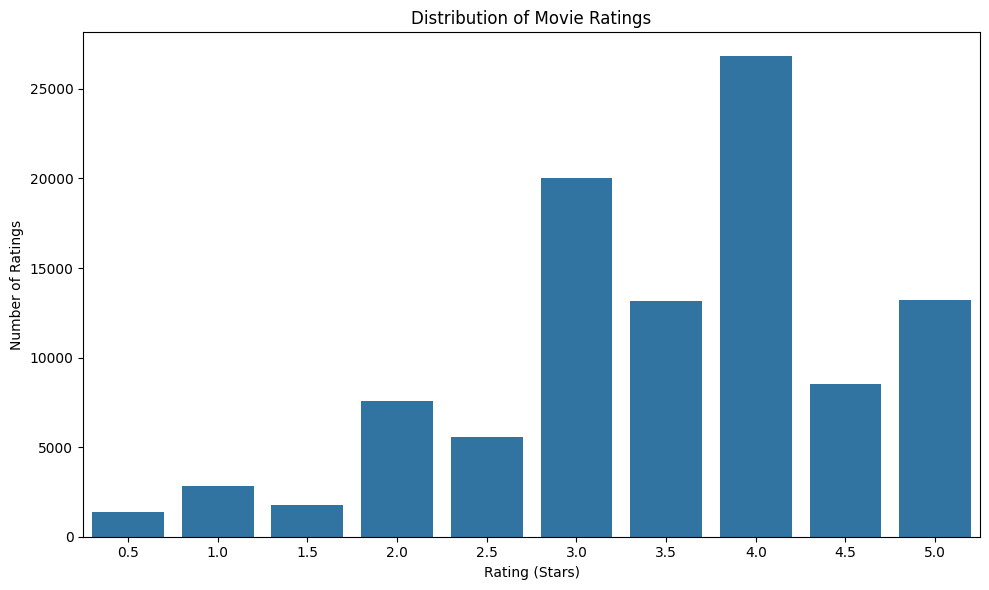

In [17]:
# Count how many times each rating was given
rating_counts = movie_data["rating"].value_counts().sort_index()

# Display the rating counts
print("Distribution of Movie Ratings:")
print(rating_counts)

# Create a bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Ratings")

plt.tight_layout()
plt.show()

Top 10 Highest-Rated Movies (At Least 50 Ratings):


,title,average_rating,total_ratings
277,"Shawshank Redemption, The (1994)",4.43,317
659,"Godfather, The (1972)",4.29,192
2224,Fight Club (1999),4.27,218
974,Cool Hand Luke (1967),4.27,57
602,Dr. Strangelove or: How I Learned to Stop Worr...,4.27,97
686,Rear Window (1954),4.26,84
921,"Godfather: Part II, The (1974)",4.26,129
6298,"Departed, The (2006)",4.25,107
913,Goodfellas (1990),4.25,126
694,Casablanca (1942),4.24,100


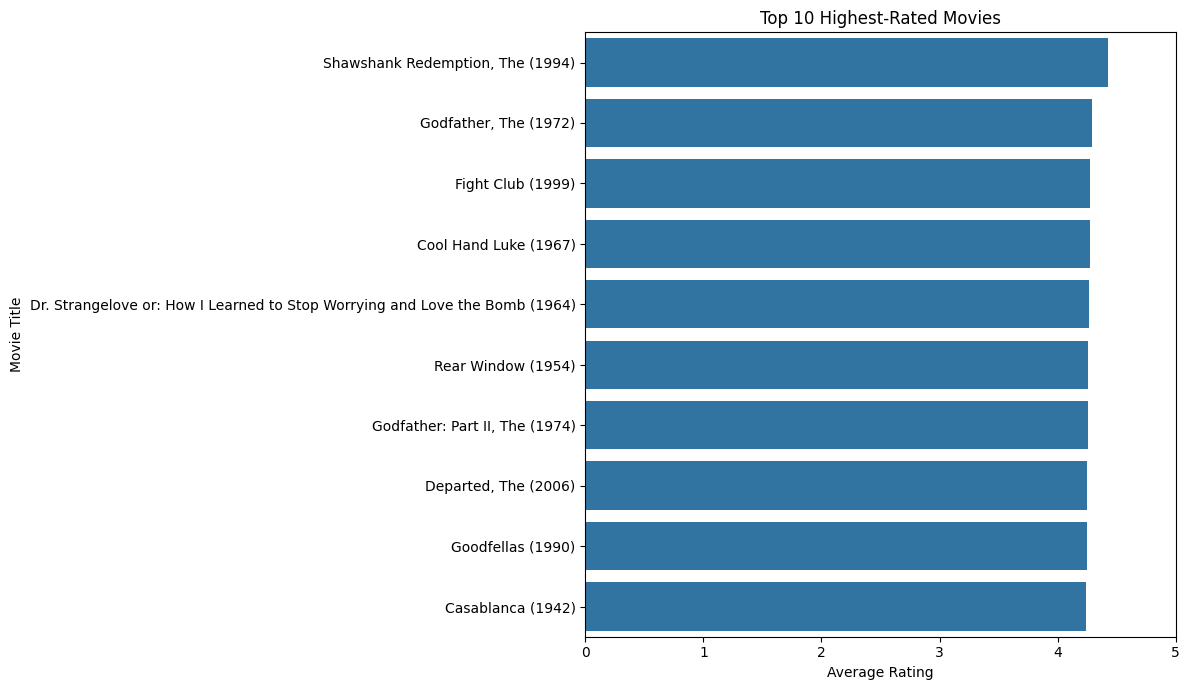

In [18]:
# Calculate the average rating and number of ratings for each movie
movie_stats = movie_data.groupby(
    ["movieId", "title"]
).agg(
    average_rating=("rating", "mean"),
    total_ratings=("rating", "count")
).reset_index()

# Consider only movies with at least 50 ratings
popular_movies = movie_stats[
    movie_stats["total_ratings"] >= 50
].copy()

# Select the top 10 highest-rated movies
top_rated_movies = popular_movies.sort_values(
    by="average_rating",
    ascending=False
).head(10)

# Display the results
print("Top 10 Highest-Rated Movies (At Least 50 Ratings):")

display(
    top_rated_movies[
        ["title", "average_rating", "total_ratings"]
    ].round(2)
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_rated_movies,
    x="average_rating",
    y="title"
)

plt.title("Top 10 Highest-Rated Movies")
plt.xlabel("Average Rating")
plt.ylabel("Movie Title")
plt.xlim(0, 5)

plt.tight_layout()
plt.show()

Top 10 Most Popular Movies:


,title,total_ratings,average_rating
314,Forrest Gump (1994),329,4.16
277,"Shawshank Redemption, The (1994)",317,4.43
257,Pulp Fiction (1994),307,4.20
510,"Silence of the Lambs, The (1991)",279,4.16
1938,"Matrix, The (1999)",278,4.19
224,Star Wars: Episode IV - A New Hope (1977),251,4.23
418,Jurassic Park (1993),238,3.75
97,Braveheart (1995),237,4.03
507,Terminator 2: Judgment Day (1991),224,3.97
461,Schindler's List (1993),220,4.22


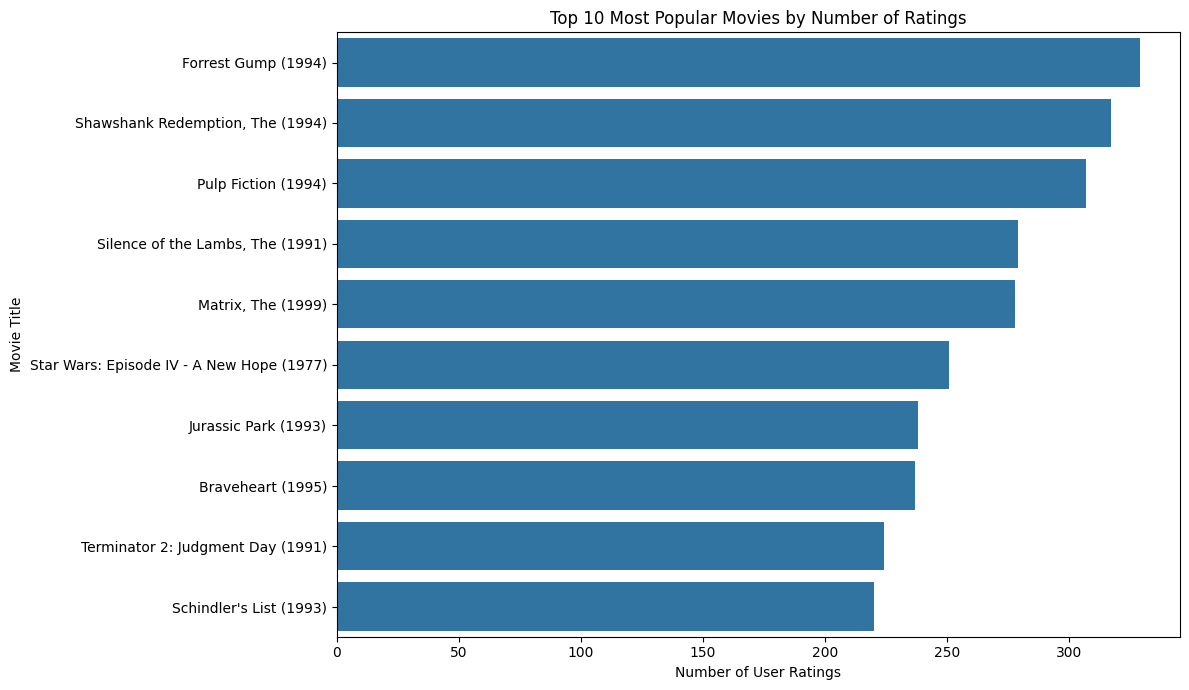

In [19]:
# Count the number of ratings for each movie
most_popular_movies = movie_stats.sort_values(
    by="total_ratings",
    ascending=False
).head(10)

# Display the top 10 most popular movies
print("Top 10 Most Popular Movies:")

display(
    most_popular_movies[
        ["title", "total_ratings", "average_rating"]
    ].round(2)
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=most_popular_movies,
    x="total_ratings",
    y="title"
)

plt.title("Top 10 Most Popular Movies by Number of Ratings")
plt.xlabel("Number of User Ratings")
plt.ylabel("Movie Title")

plt.tight_layout()
plt.show()

Top 10 Highest-Rated Genres:


,genres,average_rating,total_ratings
9,Film-Noir,3.92,870
17,War,3.81,4859
6,Documentary,3.80,1219
5,Crime,3.66,16681
7,Drama,3.66,41928
13,Mystery,3.63,7674
2,Animation,3.63,6988
11,IMAX,3.62,4145
18,Western,3.58,1930
12,Musical,3.56,4138


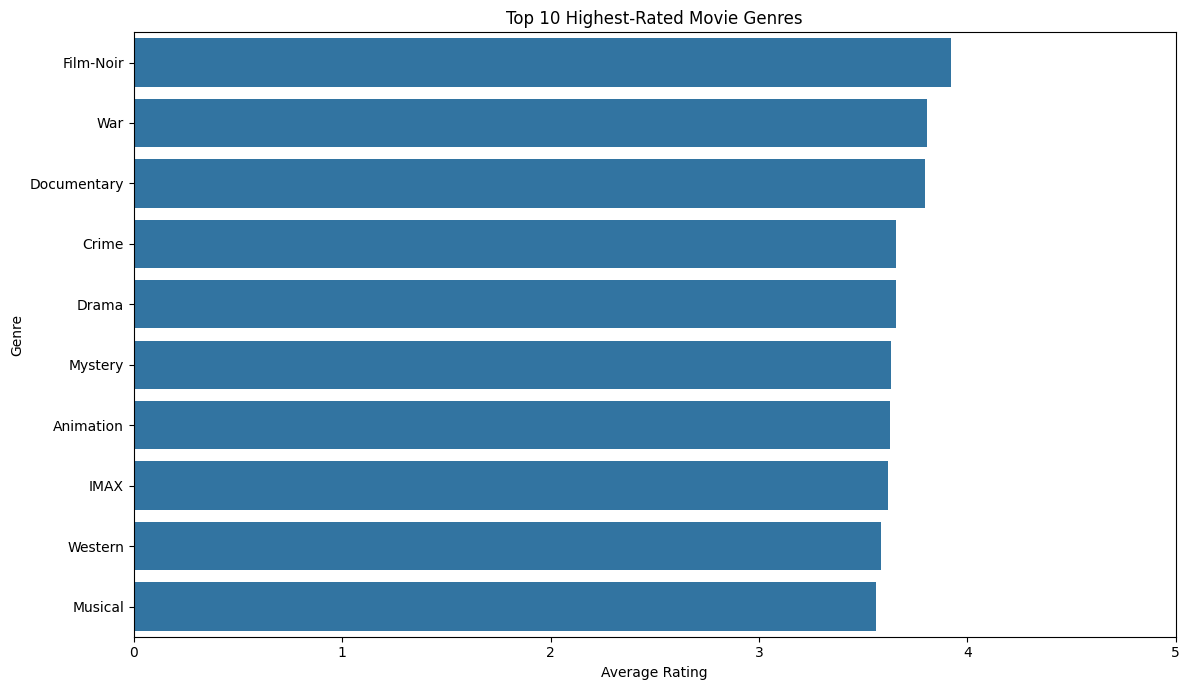

In [20]:
# Remove movies with no listed genre
genre_data = movie_data[
    movie_data["genres"].notna()
    & (movie_data["genres"] != "(no genres listed)")
].copy()

# Split movies with multiple genres into separate rows
genre_data["genres"] = genre_data["genres"].str.split("|")
genre_data = genre_data.explode("genres")

# Calculate average rating and number of ratings for each genre
genre_stats = genre_data.groupby("genres").agg(
    average_rating=("rating", "mean"),
    total_ratings=("rating", "count")
).reset_index()

# Consider genres with at least 100 ratings
popular_genres = genre_stats[
    genre_stats["total_ratings"] >= 100
].copy()

# Sort genres by average rating
top_genres = popular_genres.sort_values(
    by="average_rating",
    ascending=False
).head(10)

# Display the results
print("Top 10 Highest-Rated Genres:")

display(top_genres.round(2))

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_genres,
    x="average_rating",
    y="genres"
)

plt.title("Top 10 Highest-Rated Movie Genres")
plt.xlabel("Average Rating")
plt.ylabel("Genre")
plt.xlim(0, 5)

plt.tight_layout()
plt.show()

Average Movie Ratings by Year:


,rating_year,average_rating,total_ratings
0,1996,3.54,6040
1,1997,3.73,1916
2,1998,3.44,507
3,1999,3.77,2439
4,2000,3.39,10061
5,2001,3.51,3922
6,2002,3.61,3478
7,2003,3.50,4014
8,2004,3.51,3279
9,2005,3.43,5813


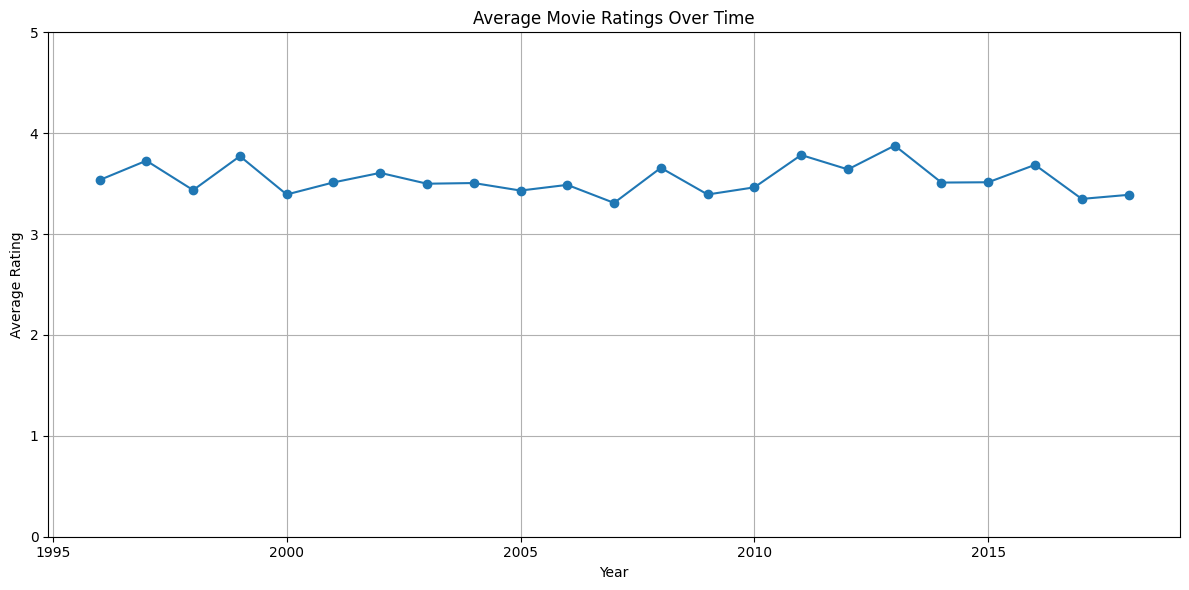

In [21]:
# Extract the year from each rating date
movie_data["rating_year"] = movie_data["rating_date"].dt.year

# Calculate average rating and number of ratings per year
yearly_ratings = movie_data.groupby("rating_year").agg(
    average_rating=("rating", "mean"),
    total_ratings=("rating", "count")
).reset_index()

# Remove records without a valid year
yearly_ratings = yearly_ratings.dropna(subset=["rating_year"])

# Display the results
print("Average Movie Ratings by Year:")
display(yearly_ratings.round(2))

# Create a line chart
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_ratings["rating_year"],
    yearly_ratings["average_rating"],
    marker="o"
)

plt.title("Average Movie Ratings Over Time")
plt.xlabel("Year")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.grid(True)

plt.tight_layout()
plt.show()

Top 10 Most Active Users:


,userId,total_ratings,average_rating
413,414,2698,3.39
598,599,2478,2.64
473,474,2108,3.40
447,448,1864,2.85
273,274,1346,3.24
609,610,1302,3.69
67,68,1260,3.23
379,380,1218,3.67
605,606,1115,3.66
287,288,1055,3.15


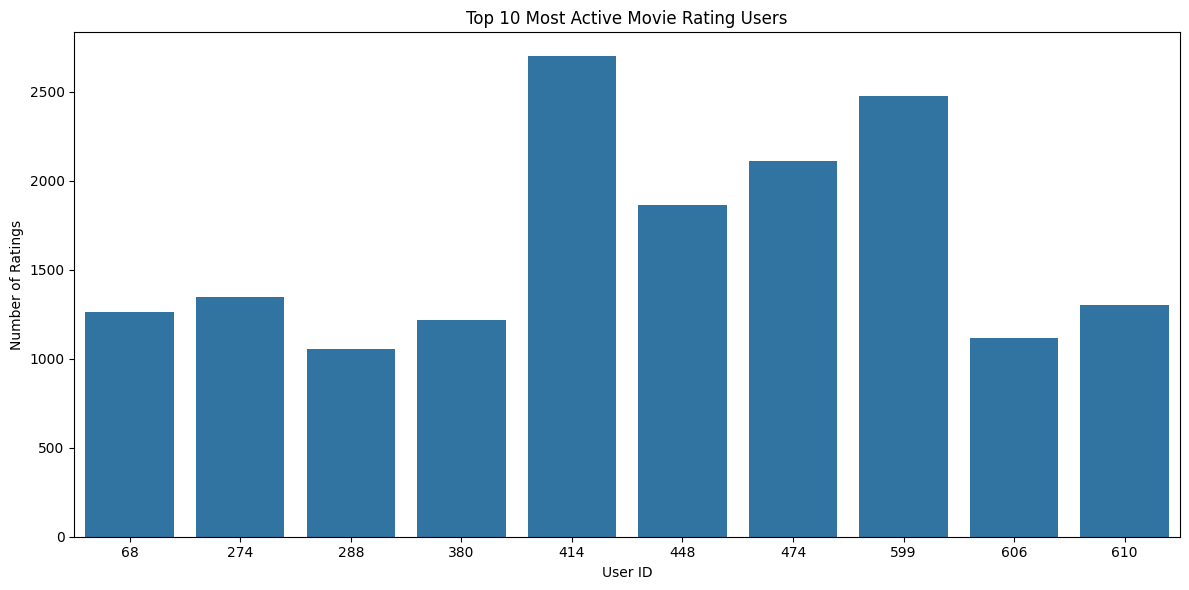

In [22]:
# Count the number of ratings submitted by each user
user_activity = movie_data.groupby("userId").agg(
    total_ratings=("rating", "count"),
    average_rating=("rating", "mean")
).reset_index()

# Select the 10 most active users
top_users = user_activity.sort_values(
    by="total_ratings",
    ascending=False
).head(10)

# Display the results
print("Top 10 Most Active Users:")

display(top_users.round(2))

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_users,
    x="userId",
    y="total_ratings"
)

plt.title("Top 10 Most Active Movie Rating Users")
plt.xlabel("User ID")
plt.ylabel("Number of Ratings")

plt.tight_layout()
plt.show()

Top 10 Most Popular Movie Genres:


,genres,total_ratings,average_rating
7,Drama,41928,3.66
4,Comedy,39053,3.38
0,Action,30635,3.45
16,Thriller,26452,3.49
1,Adventure,24161,3.51
14,Romance,18124,3.51
15,Sci-Fi,17243,3.46
5,Crime,16681,3.66
8,Fantasy,11834,3.49
3,Children,9208,3.41


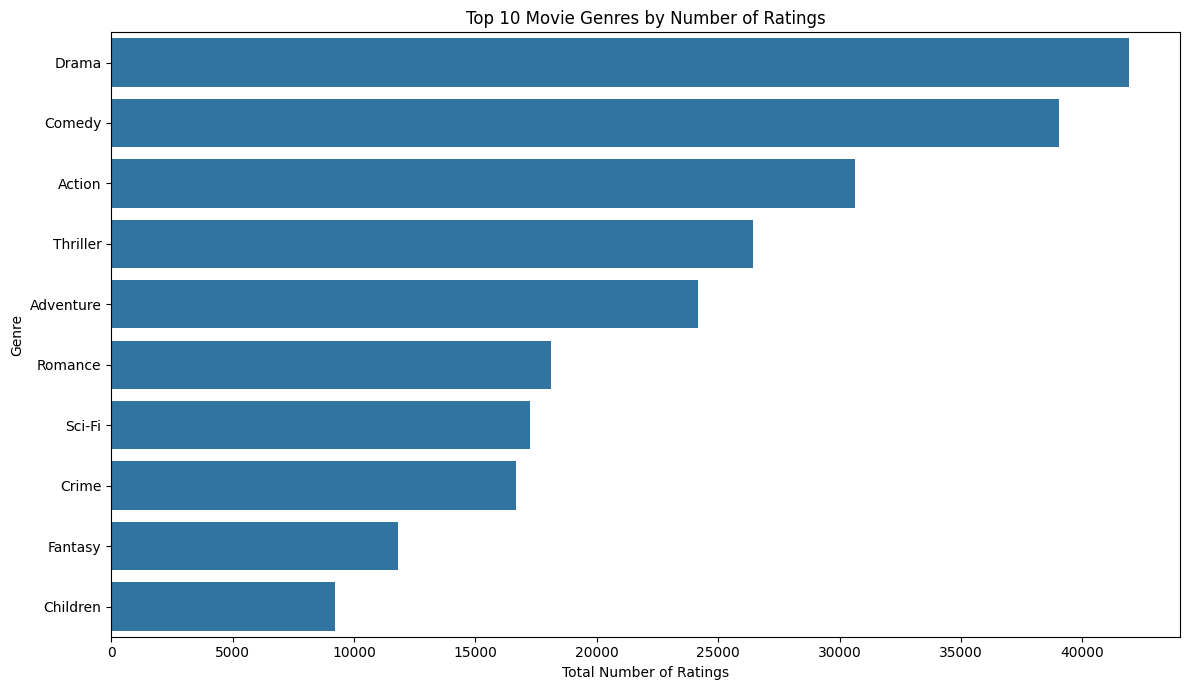

In [23]:
# Calculate the total number of ratings for each genre
genre_popularity = genre_data.groupby("genres").agg(
    total_ratings=("rating", "count"),
    average_rating=("rating", "mean")
).reset_index()

# Select the top 10 most popular genres
top_popular_genres = genre_popularity.sort_values(
    by="total_ratings",
    ascending=False
).head(10)

# Display the results
print("Top 10 Most Popular Movie Genres:")

display(top_popular_genres.round(2))

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_popular_genres,
    x="total_ratings",
    y="genres"
)

plt.title("Top 10 Movie Genres by Number of Ratings")
plt.xlabel("Total Number of Ratings")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

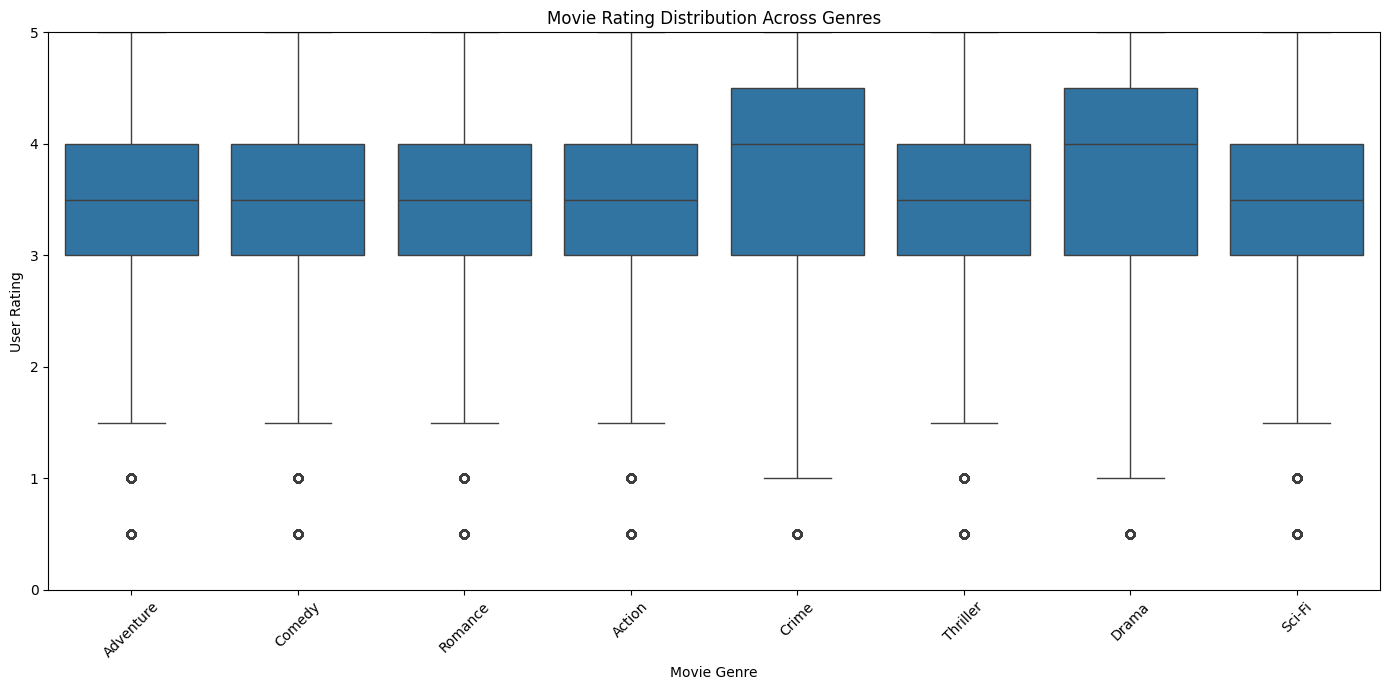

In [24]:
# Select the 8 genres with the most ratings
top_8_genres = (
    genre_data["genres"]
    .value_counts()
    .head(8)
    .index
)

# Filter the dataset to include only these genres
genre_rating_data = genre_data[
    genre_data["genres"].isin(top_8_genres)
].copy()

# Create a box plot
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=genre_rating_data,
    x="genres",
    y="rating"
)

plt.title("Movie Rating Distribution Across Genres")
plt.xlabel("Movie Genre")
plt.ylabel("User Rating")
plt.ylim(0, 5)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

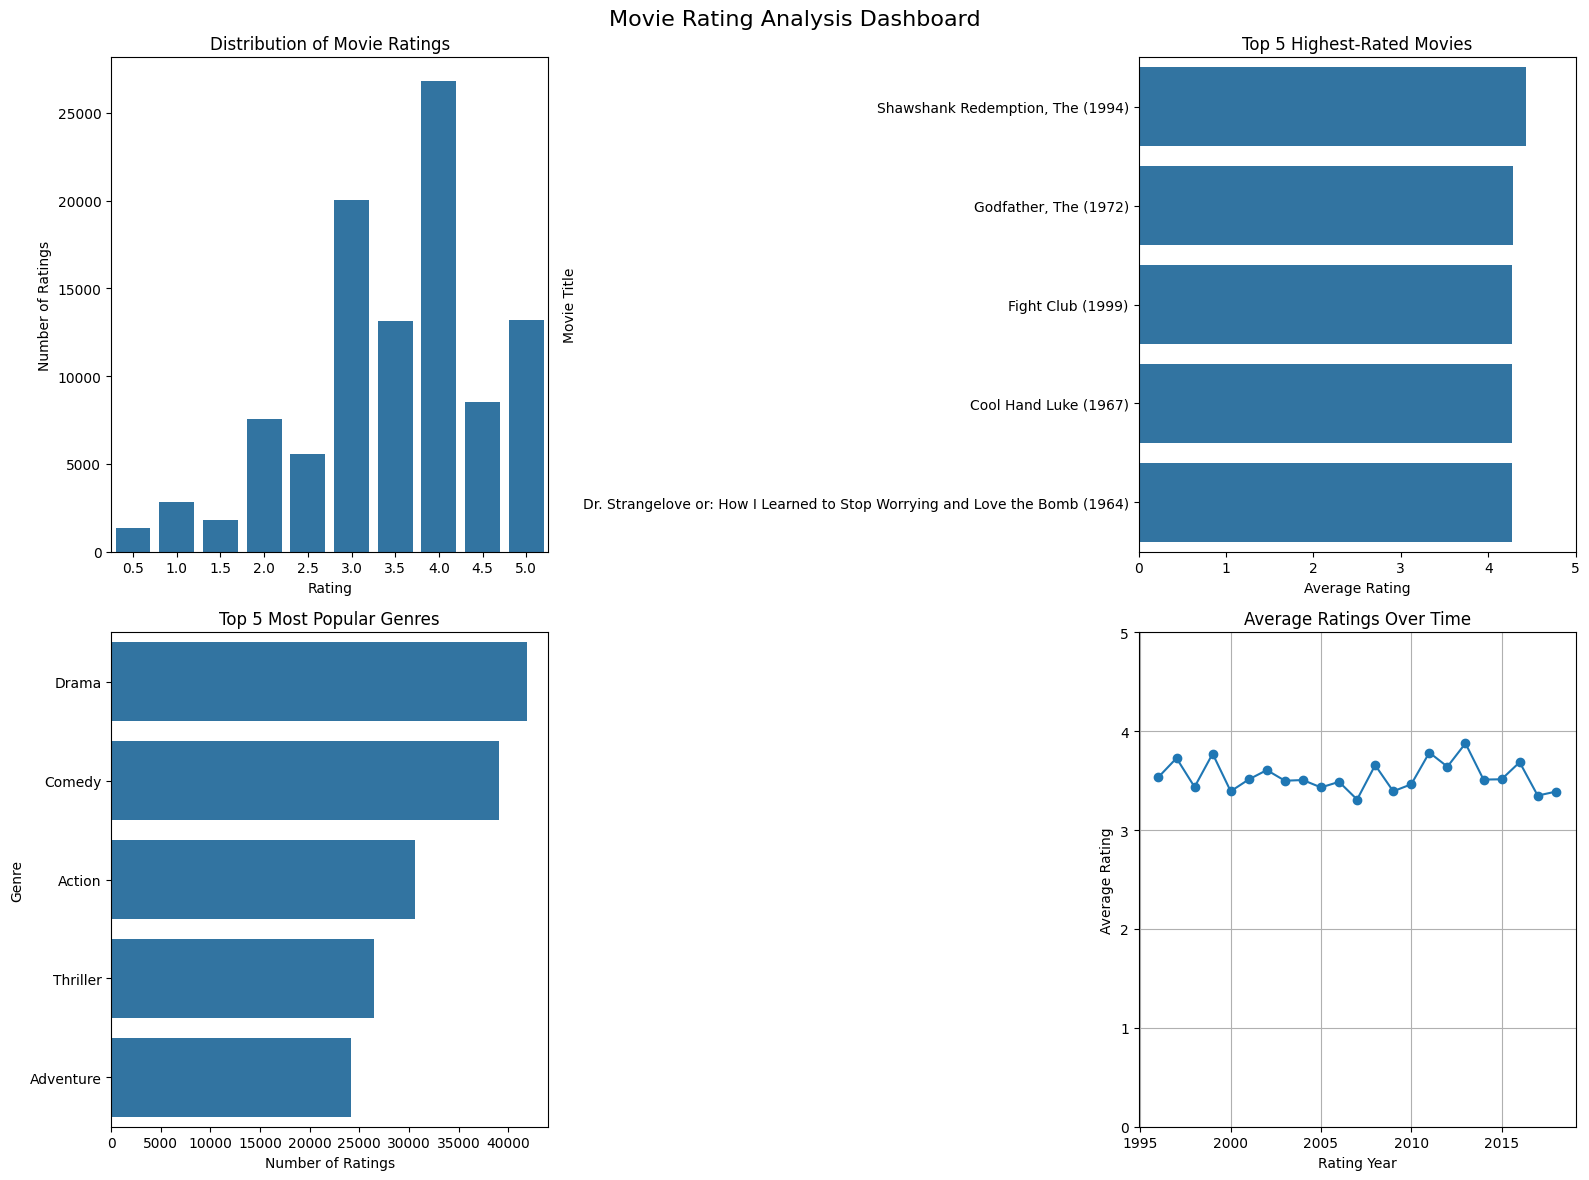

In [25]:
# Create a 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribution of ratings
rating_counts = movie_data["rating"].value_counts().sort_index()

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Distribution of Movie Ratings")
axes[0, 0].set_xlabel("Rating")
axes[0, 0].set_ylabel("Number of Ratings")

# 2. Top 5 highest-rated movies
top_5_movies = top_rated_movies.head(5)

sns.barplot(
    data=top_5_movies,
    x="average_rating",
    y="title",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Top 5 Highest-Rated Movies")
axes[0, 1].set_xlabel("Average Rating")
axes[0, 1].set_ylabel("Movie Title")
axes[0, 1].set_xlim(0, 5)

# 3. Top 5 popular genres
top_5_popular_genres = top_popular_genres.head(5)

sns.barplot(
    data=top_5_popular_genres,
    x="total_ratings",
    y="genres",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Top 5 Most Popular Genres")
axes[1, 0].set_xlabel("Number of Ratings")
axes[1, 0].set_ylabel("Genre")

# 4. Average ratings over time
axes[1, 1].plot(
    yearly_ratings["rating_year"],
    yearly_ratings["average_rating"],
    marker="o"
)

axes[1, 1].set_title("Average Ratings Over Time")
axes[1, 1].set_xlabel("Rating Year")
axes[1, 1].set_ylabel("Average Rating")
axes[1, 1].set_ylim(0, 5)
axes[1, 1].grid(True)

# Final layout
fig.suptitle("Movie Rating Analysis Dashboard", fontsize=16)

plt.tight_layout()
plt.show()

In [26]:
# Calculate overall statistics
total_ratings = len(movie_data)
total_movies = movie_data["movieId"].nunique()
total_users = movie_data["userId"].nunique()

overall_average_rating = movie_data["rating"].mean()

# Find the most frequently rated movie
most_rated_movie = movie_stats.loc[
    movie_stats["total_ratings"].idxmax()
]

# Find the highest-rated movie from our filtered list
highest_rated_movie = top_rated_movies.iloc[0]

# Find the most popular genre
most_popular_genre = top_popular_genres.iloc[0]

# Display the project summary
print("=" * 55)
print("MOVIE RATING ANALYSIS - PROJECT SUMMARY")
print("=" * 55)

print(f"\nTotal Ratings Analyzed: {total_ratings:,}")
print(f"Total Movies Rated: {total_movies:,}")
print(f"Total Users: {total_users:,}")

print(f"\nOverall Average Rating: {overall_average_rating:.2f} / 5")

print("\nMost Frequently Rated Movie:")
print(f"Title: {most_rated_movie['title']}")
print(f"Number of Ratings: {most_rated_movie['total_ratings']}")

print("\nHighest-Rated Movie (At Least 50 Ratings):")
print(f"Title: {highest_rated_movie['title']}")
print(f"Average Rating: {highest_rated_movie['average_rating']:.2f}")

print("\nMost Popular Genre:")
print(f"Genre: {most_popular_genre['genres']}")
print(f"Number of Ratings: {most_popular_genre['total_ratings']:,}")

print("\nVisualizations Created:")
print("1. Distribution of Movie Ratings")
print("2. Top 10 Highest-Rated Movies")
print("3. Top 10 Most Popular Movies")
print("4. Highest-Rated Genres")
print("5. Average Ratings Over Time")
print("6. Most Active Users")
print("7. Most Popular Genres")
print("8. Rating Distribution Across Genres")
print("9. Movie Rating Analysis Dashboard")

print("\nProject Status: Analysis Completed")
print("=" * 55)

MOVIE RATING ANALYSIS - PROJECT SUMMARY

Total Ratings Analyzed: 100,836
Total Movies Rated: 9,724
Total Users: 610

Overall Average Rating: 3.50 / 5

Most Frequently Rated Movie:
Title: Forrest Gump (1994)
Number of Ratings: 329

Highest-Rated Movie (At Least 50 Ratings):
Title: Shawshank Redemption, The (1994)
Average Rating: 4.43

Most Popular Genre:
Genre: Drama
Number of Ratings: 41,928

Visualizations Created:
1. Distribution of Movie Ratings
2. Top 10 Highest-Rated Movies
3. Top 10 Most Popular Movies
4. Highest-Rated Genres
5. Average Ratings Over Time
6. Most Active Users
7. Most Popular Genres
8. Rating Distribution Across Genres
9. Movie Rating Analysis Dashboard

Project Status: Analysis Completed


# Conclusion

The Movie Rating Analysis project explored movie ratings using the MovieLens dataset.

The main findings of this project are:

1. Analyzed movie ratings to understand users' rating patterns.
2. Identified the highest-rated movies with at least 50 ratings.
3. Found the most popular movies based on the number of ratings.
4. Compared average ratings across different movie genres.
5. Studied changes in average ratings over time.
6. Identified users who submitted the most ratings.
7. Compared rating distributions across movie genres.
8. Created visualizations and a dashboard to present the findings.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## Dataset

MovieLens Latest Small Dataset provided by GroupLens Research.

## Final Outcome

This project demonstrates how data analysis and visualization can help us understand movie preferences, rating patterns, and genre popularity.